# 01 — Understand the tourism data

## What the data can tell us

We have attraction details, user profiles and reviews with ratings. We can see which places someone reviewed and what score they gave. We do not have a complete record of their trips.

| What is missing | What we do about it |
|---|---|
| Complete visits, travel order and reliable trip dates | Use reviews to describe interests; do not reconstruct a real itinerary. A review's publication date is not its visit date. |
| Searches, current plans and current user location | Ask for a destination and, when needed, interests. Do not pretend old reviews tell us what someone wants on this trip. |
| Accurate coordinates for each attraction | Filter by city. Many places share a city coordinate, so we cannot reliably rank the nearest attractions. |
| Recommendations shown, clicks and later bookings or visits | Generate and inspect suggestions. We cannot tell whether people followed them or whether they caused extra visits. |
| Year-by-year attraction details | Use the categories supplied in the file. We cannot check whether a place had the same category in an earlier year. |

Our goal is to help a tourist find places worth considering in a chosen city. Missing data determines how far we can take that product. More reviews do not automatically mean more visitors, and fewer reviews do not prove a place is uncrowded.

## Which notebook to use

| Notebook | What you get |
|---|---|
| **01 Data Playground** | Explore each table, connect the tables, and inspect distributions, maps and data problems. |
| **02 Recommendation Baselines** | See how personal interests, similar travellers and a new visitor's stated interests lead to suggestions. |
| **02 Cosine vs Transformer Workbench** | Keep and inspect the earlier three-method comparison. This file is retained. |
| **03 Transformer Workbench** | A separate copy of the advanced experiment. Further training is paused. |

The separate clustering notebook shows the earlier group-based approach. Those groups are not currently used by the three-route baseline notebook.

## What this notebook does

Inspect **Users → Attractions → Reviews → travelHistory**, then connect them. We use all four original CSV files and all their recorded dates. The recommendation experiments use a smaller, prepared 2010–2019 subset, so their counts can differ.

Each section shows the fields, actual rows, missing values and useful plots. The final sections show how much history each person has, where reviews concentrate and one person's records.

Use the **Tourism ML (persistent CPU)** kernel. Run cells from the top with Shift+Enter, or choose Run → Run All Cells. Reading the full review file can take several minutes. Results are saved in `Current/interactive/eda_outputs`.

## 0. Check the files and prepare the charts

Compare file hashes with the saved download record to check that we are reading the same files. Then prepare the chart and lookup functions.

In [ ]:
# Purpose: 01 — Understand the tourism data
# The steps below keep the calculation visible; read the saved tables or plots after this cell.

from pathlib import Path
import os,json,time,hashlib,collections,gc
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import LogNorm
from IPython.display import display,Image,Markdown


# Find the project from the current folder so the notebook does not need a personal absolute path.
LAB=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'assets/baseline_data').exists())


# Keep original CSV inputs separate from the tables and figures generated below.
RAW=LAB/'assets/raw_incultum'
OUT=Path(os.environ.get('TOURISM_EDA_OUTPUT',LAB/'Current/interactive/eda_outputs'))
OUT.mkdir(parents=True,exist_ok=True)


# Read 200,000 rows at a time; this bounds memory when scanning the multi-gigabyte CSVs.
NA=['','NA','NaN','nan'];CHUNK=200000;START=time.perf_counter()


# Use the earlier download hashes to check the original files before interpreting their contents.
expected=json.loads((LAB.parent/'Research/Tripadvisor_EDA/Outputs/download_receipt.json').read_text())
source_check=[]


# Hash each complete source file, not just its first rows. Stop if a file is missing or changed.
for v in expected.values():
    p=RAW/Path(v['zip_name']).name
    if not p.exists():raise FileNotFoundError(f'Restore the original module first: {p}. Run source/restore_raw_incultum.py.')
    h=hashlib.sha256()
    with p.open('rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):h.update(b)
    assert h.hexdigest()==v['sha256'],p
    source_check.append({'file':p.name,'bytes':p.stat().st_size,'original_sha256_matches':True})
display(pd.DataFrame(source_check))


# Load source columns as text first so IDs, missing values and malformed numbers are not silently reinterpreted.
def read(name,**kwargs):return pd.read_csv(RAW/name,dtype=str,keep_default_na=False,na_values=NA,**kwargs)


# Save a small JSON summary for later checks without changing the source CSVs.
def save(name,obj):(OUT/name).write_text(json.dumps(obj,indent=2,default=str))
figures=[]


# Save the PNG and optional chart-source table, then display the same image inline.
def figure(name,fig,table=None):
    fig.tight_layout();fig.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight');plt.close(fig)
    if table is not None:table.to_csv(OUT/(name+'.csv'),index=True)
    figures.append(name);display(Image(filename=str(OUT/(name+'.png'))))


# Show the largest categories in a readable horizontal chart; export the counts used to draw it.
def bars(series,title,xlabel,name,limit=20):
    s=series.sort_values(ascending=False).head(limit).iloc[::-1]
    fig,ax=plt.subplots(figsize=(10,max(3,len(s)*.28)))
    ax.barh([str(x)[:65] for x in s.index],s.values,color='#4477AA')
    ax.set(title=title,xlabel=xlabel);figure(name,fig,s.rename('count').to_frame())


# Return and save missing-value counts and percentages using this table's row count as the denominator.
def missing_table(name,count,rows):
    frame=pd.DataFrame({'field':list(count),'missing':[int(count[k]) for k in count]})
    frame['missing_pct']=100*frame.missing/rows;frame.to_csv(OUT/(name+'_missing.csv'),index=False)
    display(frame);return frame


# Match values to a sorted ID lookup. Return positions plus a mask; positions alone can refer to insertion points, not real matches.
def match(sorted_keys,values):
    ix=np.searchsorted(sorted_keys,values);ok=ix<len(sorted_keys)
    ok[ok]&=sorted_keys[ix[ok]]==values[ok]
    return ix,ok


# Use left-closed intervals so each count belongs to exactly one labelled range.
def count_bins(values,edges,labels):
    return pd.Series(pd.cut(values,edges,labels=labels,right=False)).value_counts(sort=False)


# Draw country outlines as a background only; these shapes contain no tourist observations.
def world_map(ax):
    geo=json.loads((LAB/'assets/world_countries.geojson').read_text());patches=[]
    for f in geo['features']:
        g=f['geometry'];polys=[g['coordinates']] if g['type']=='Polygon' else g['coordinates'] if g['type']=='MultiPolygon' else []
        for p in polys:patches.append(Polygon(np.array(p[0]),closed=True))
    ax.add_collection(PatchCollection(patches,facecolor='#F1F1ED',edgecolor='#AAAAAA',linewidth=.35,zorder=0))
    ax.set(xlim=(-26,40),ylim=(33,72),xlabel='Longitude',ylabel='Latitude')
    ax.grid(alpha=.15);return ax
summary={};print('Four complete original tables; descriptive scope, not the 2010–2017 training partition.')



### Findings — the source files are consistent

All four original CSV hashes match the earlier download record. The charts below therefore use the same source files as the earlier full-file analysis. This is a file check; it does not establish that every field is accurate.

# 1. Users — what do we know about each person?

Read `users.csv`, show examples, and count missing fields. Some IDs appear more than once. Build one lookup row per ID so that joining a review to a user does not accidentally duplicate the review. If repeated rows disagree on a nonmissing value, mark that value unknown.

`numReviews` is the platform's reported total at collection time. Later we count how many reviews each person actually has in these files.

In [ ]:
# Purpose: 1. Users — what do we know about each person?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Collect compact arrays per chunk, then build one lookup entry per user ID.
ids=[];days=[];totals=[];user_missing=collections.Counter();user_fields={};user_rows=0


# Scan every user-profile row; the first few displayed rows are examples, not a representative sample.
for j,d in enumerate(read('users.csv',chunksize=CHUNK)):
    if j==0:display(d.head());user_fields={c:str(d[c].dtype) for c in d}
    user_rows+=len(d);user_missing.update(d.isna().sum().to_dict())

    # Fixed-width bytes reduce memory for millions of IDs; use the same representation when matching reviews.
    ids.append(d.userID.fillna('').to_numpy(dtype='S64'))
    dt=pd.to_datetime(d.joinDate,format='mixed',errors='coerce')

    # Store dates as integer days. The sentinel -2147483648 means unknown, not an actual date.
    day=dt.to_numpy(dtype='datetime64[D]').astype(np.int64)
    days.append(np.where(dt.notna(),day,-2147483648).astype(np.int32))
    totals.append(pd.to_numeric(d.numReviews.str.replace(',','',regex=False),errors='coerce').to_numpy(dtype=np.float32))


# Combine chunk arrays only after parsing; release the larger temporary objects when no longer needed.
raw_uid=np.concatenate(ids);raw_join=np.concatenate(days);raw_total=np.concatenate(totals)
del ids,days,totals,d;gc.collect()


# uid contains unique sorted IDs; inverse maps each original row to its user so duplicate profiles do not multiply joins.
uid,first_index,inverse=np.unique(raw_uid,return_index=True,return_inverse=True)
assert not (uid==b'').any();NU=len(uid)


# Compare the minimum and maximum nonmissing dates for every repeated ID; disagreement makes the date unknown.
low=np.full(NU,2147483647,dtype=np.int32);high=np.full(NU,-2147483648,dtype=np.int32)
np.minimum.at(low,inverse,np.where(raw_join==-2147483648,2147483647,raw_join))
np.maximum.at(high,inverse,raw_join)
join_conflict=(low!=high)&(high!=-2147483648)
join_day=np.where((low==high)&(high!=-2147483648),low,-2147483648).astype(np.int32)
review_total=raw_total[first_index].copy()
total_low=np.full(NU,np.inf,dtype=np.float32);total_high=np.full(NU,-np.inf,dtype=np.float32)


# Ignore missing totals when checking disagreements. Conflicting platform totals must not become a made-up single value.
np.minimum.at(total_low,inverse,np.nan_to_num(raw_total,nan=np.inf))
np.maximum.at(total_high,inverse,np.nan_to_num(raw_total,nan=-np.inf))
total_conflict=np.isfinite(total_low)&(total_low!=total_high)
review_total[total_conflict]=np.nan


# Report raw rows, unique users and conflicts separately; these are different quantities.
summary['users']={'rows':user_rows,'unique_ids':NU,'duplicate_key_extra_rows':user_rows-NU,
    'conflicting_nonmissing_join_dates':int(join_conflict.sum()),'conflicting_numReviews':int(total_conflict.sum()),
    'join_policy':'One canonical ID; conflicting nonmissing dates or platform totals become missing; original rows unchanged.'}
display(pd.Series(summary['users']).to_frame('value'));missing_table('users',user_missing,user_rows)
user_samples=pd.DataFrame({'userID':uid[:5].astype(str),'numReviews':review_total[:5],
    'joinDate':pd.to_datetime(np.where(join_day[:5]==-2147483648,np.iinfo(np.int64).min,join_day[:5].astype(np.int64)),unit='D')})
display(user_samples)
del raw_uid,raw_join,raw_total,inverse,first_index,low,high,total_low,total_high;gc.collect()



### Findings — profile rows are not unique people

There are **6,981,081 profile rows but 6,704,433 different IDs**: 276,648 rows repeat an ID. Joining reviews directly to the raw profile table could multiply records. We therefore use one lookup row per user.

After parsing comma-formatted totals, 4,275 users have conflicting nonmissing platform review totals. These totals become unknown. We do not use them to measure attraction activity; we count the actual reviews instead.

## 1.1 When did users join, and how many reviews does the platform report?

Plot registration years and reported review totals using the one-row-per-ID lookup. Show unknown values separately. The user table does not contain home coordinates or a primary-language field.

In [ ]:
# Purpose: 1.1 When did users join, and how many reviews does the platform report?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Remove unknown date sentinels before converting integer days back to calendar dates.
valid_join=join_day!=-2147483648
signup=pd.to_datetime(join_day[valid_join].astype(np.int64),unit='D')
signup_counts=pd.Series(signup.year).value_counts().sort_index()
fig,ax=plt.subplots(figsize=(11,3.5));ax.bar(signup_counts.index,signup_counts.values,color='#4477AA')
ax.set(title='Users: registration year, one canonical profile per user',xlabel='Registration year',ylabel='Users')
figure('users_registration_year',fig,signup_counts.rename('users').to_frame())


# These are platform-reported totals, not the observed number of attraction reviews in our files.
reported=count_bins(review_total[np.isfinite(review_total)],[-.5,.5,1.5,5,10,50,200,np.inf],['0','1','2–4','5–9','10–49','50–199','200+'])
fig,ax=plt.subplots(figsize=(10,3.5));reported.plot.bar(ax=ax,color='#4477AA',rot=0)
ax.set(title='Users: reported platform-wide review total',xlabel='numReviews (not this dataset’s observed activity)',ylabel='Canonical users with nonconflicting numeric totals')
figure('users_reported_review_totals',fig,reported.rename('users').to_frame())
print('Unknown/conflicting platform totals:',int(np.isnan(review_total).sum()))
print('User language, home coordinates and primary language are not columns in users.csv.')
del signup;gc.collect()



### Findings — registration history is not preference history

Among known signup years, 2015 is the largest group, with 792,094 users;2016 follows with 770,822. The platform reports one review for 1,250,356 users, while 60,701 platform totals are missing or conflicting.

These figures describe account records and platform totals, not how many useful attraction choices we know for each person. The connected-review section below is needed before choosing a recommendation route. There is no primary-language or home-coordinate column to use here.

# 2. Attractions — what places are in the data?

Show all 34 fields, example rows and missing values. Check that each attraction ID identifies one place. Keep all 20 category columns because one place may have several labels. Check missing categories before replacing them with zeros for calculations.

In [ ]:
# Purpose: 2. Attractions — what places are in the data?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Sort by attraction ID once so the metadata rows, category rows and later lookup indices stay aligned.
attrs=read('attr.csv').sort_values('attractionID').reset_index(drop=True)
assert attrs.attractionID.is_unique and attrs.attractionID.notna().all()


# NI counts catalogue attractions. CATEGORIES selects the twenty source label columns, not ratings or popularity.
NI=len(attrs);aid=attrs.attractionID.to_numpy(dtype='S36');CATEGORIES=list(attrs.columns[12:32])


# Make a numeric attraction-by-category matrix. Missing cells become zero for calculations, not verified category absence.
category=attrs[CATEGORIES].apply(pd.to_numeric,errors='coerce').fillna(0).to_numpy(dtype=np.float32)
assert np.isin(category,[0,1]).all()


# Parse coordinates and reject missing or out-of-range values; this does not prove they locate individual attractions.
lat=pd.to_numeric(attrs.latitude,errors='coerce');lon=pd.to_numeric(attrs.longitude,errors='coerce')
valid_geo=lat.between(-90,90)&lon.between(-180,180)
display(attrs.head());display(pd.DataFrame({'field':attrs.columns,'dtype':[str(attrs[c].dtype) for c in attrs]}))
missing_table('attractions',attrs.isna().sum().to_dict(),NI)
summary['attractions']={'rows':NI,'unique_ids':int(attrs.attractionID.nunique()),'zero_category_rows':int((category.sum(axis=1)==0).sum()),
    'category_missing_cells_encoded_zero':int(attrs[CATEGORIES].isna().sum().sum()),'complete_valid_coordinates':int(valid_geo.sum())}
display(pd.Series(summary['attractions']).to_frame('value'))
print('Categories overlap. Zero-encoding missing categories is a display representation, not proof of absence.')



### Findings — categories are the strongest starting feature

All **321,055 attraction IDs are unique**. Only 1,142 attractions have no recorded category labels, so categories can cover most places in a first content-based approach.

Other fields are much less complete: **99.86% of prices, 82.10% of descriptions and 62.70% of suggested durations are missing**. We can start with category interests, but cannot offer reliable budget filtering or full-catalogue text recommendations from these fields alone. Missing price does not mean free.

## 2.1 What kinds of places do we have?

Compare countries, cities, categories, ratings, review totals and suggested visit durations. Category counts overlap: one place can count as both a park and an outdoor activity. Suggested duration describes a place, not how long any particular tourist stayed.

In [ ]:
# Purpose: 2.1 What kinds of places do we have?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Compare the source catalogue's coverage across countries, not national tourist volumes.
bars(attrs.country.value_counts(),'Attractions by source country','Catalogue attractions','attractions_country')
bars(attrs.locationAttraction.value_counts(),'Locations with the most catalogue attractions','Catalogue attractions','attractions_locations',20)
bars(pd.Series(category.sum(axis=0),index=CATEGORIES),'Overlapping attraction categories','Attractions with category flag','attractions_categories',20)
fig,axes=plt.subplots(1,2,figsize=(12,4))
rating=pd.to_numeric(attrs.rating,errors='coerce');rating.value_counts().sort_index().plot.bar(ax=axes[0],color='#4477AA')
axes[0].set(title='Catalogue average rating',xlabel='Reported rating',ylabel='Attractions')


# Use log10(1 + count) to display a long tail while keeping zero-review attractions visible.
declared=pd.to_numeric(attrs.noReviews,errors='coerce');axes[1].hist(np.log10(1+declared.dropna()),bins=45,color='#228833')
axes[1].set(title='Catalogue review totals: long tail',xlabel='log10(1 + noReviews)',ylabel='Attractions')
figure('attractions_rating_and_attention',fig,pd.DataFrame({'rating':rating,'catalogue_noReviews':declared}))
bars(attrs.duration.fillna('<missing>').value_counts(),'Suggested attraction duration','Attractions','attractions_duration',8)
print('Suggested duration is not actual time spent; noReviews is a catalogue snapshot, not the core-review row count.')



### Findings — the catalogue is uneven

Italy has 122,477 attractions, France 78,070 and Spain 56,340. Together they account for **80.01% of catalogue rows**. Overall patterns will therefore reflect these countries much more than the smaller sources.

Sights/landmarks is the largest category, at 116,276 places, followed by Tours at 50,637. These labels overlap. “Features animalsLearn more about animal welfare in tourism” also appears 627 times in the duration field; it is not a visit duration and needs cleaning before use.

## 2.2 Where are the places?

Draw Europe and world maps. Group records that share the same coordinate; the size and colour of each dot show how many attraction records use it. The world map also shows records outside the Europe view.

In [ ]:
# Purpose: 2.2 Where are the places?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Aggregate identical coordinates first; one map dot can represent many different catalogue places.
geo=pd.DataFrame({'latitude':lat[valid_geo],'longitude':lon[valid_geo]}).value_counts().rename('attractions').reset_index()
fig,ax=plt.subplots(figsize=(11,7));world_map(ax)
sc=ax.scatter(geo.longitude,geo.latitude,s=4+5*np.log1p(geo.attractions),c=geo.attractions,cmap='viridis',norm=LogNorm(vmin=1,vmax=max(2,int(geo.attractions.max()))),alpha=.65,zorder=2)
fig.colorbar(sc,ax=ax,label='Attraction records sharing the source coordinate')
ax.set_title('Catalogue geography: Europe view (shared coordinates aggregated)')
figure('attractions_source_coordinate_map',fig,geo)


# Count records outside the Europe zoom so the map does not silently hide them.
within=(geo.longitude.between(-26,40)&geo.latitude.between(33,72))
print('Attraction records outside the Europe viewport:',int(geo.loc[~within,'attractions'].sum()))
print('Map basemap: Natural Earth public-domain 1:110m countries; source: https://github.com/nvkelso/natural-earth-vector')
fig,ax=plt.subplots(figsize=(11,4.5));ax.scatter(geo.longitude,geo.latitude,s=3+2*np.log1p(geo.attractions),alpha=.5)
ax.set(xlim=(-180,180),ylim=(-90,90),xlabel='Longitude',ylabel='Latitude',title='Global source-coordinate extent (includes records outside Europe)');ax.grid(alpha=.2)
figure('attractions_global_extent',fig)



### Findings — catalogue coverage extends beyond the Europe view

The Europe map excludes 6,486 attraction records outside its displayed bounds; the world view keeps them visible. Dot size counts records sharing a coordinate, not nearby entrances.

A large dot may reflect reused city coordinates rather than a physical concentration of attractions. Check coordinate reuse before interpreting the map as local supply.

## 2.3 Are these exact attraction coordinates?

Count how many different coordinates each city has, and check Paris in detail. If thousands of different places share one coordinate, it is probably a city marker. We should not display it as the exact entrance of every attraction.

In [ ]:
# Purpose: 2.3 Are these exact attraction coordinates?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Inspect coordinate reuse within a named location, not just global coordinate validity.
location_geo=attrs.loc[valid_geo,['locationAttraction']].copy()
location_geo['latitude']=lat[valid_geo];location_geo['longitude']=lon[valid_geo]
coord_counts=location_geo.groupby(['locationAttraction','latitude','longitude'],dropna=False).size().rename('records').reset_index()
locations=coord_counts.groupby('locationAttraction').agg(attractions=('records','sum'),unique_coordinate_pairs=('records','size'),most_shared_coordinate=('records','max'))


# A share near one means most places in that location use the same coordinate; exact proximity would be misleading.
locations['largest_coordinate_share']=locations.most_shared_coordinate/locations.attractions
display(locations.sort_values('attractions',ascending=False).head(20))
locations.to_csv(OUT/'location_coordinate_quality.csv')


# Use the exact Paris label; a prefix match can include names such as Parisot.
paris=attrs.locationAttraction.eq('France/Paris')
display(pd.DataFrame({'latitude':lat[paris],'longitude':lon[paris]}).value_counts(dropna=False).head(10).rename('Paris attractions').to_frame())
bars(geo.set_index(['latitude','longitude']).attractions,'Most reused source coordinates','Attraction records','coordinate_reuse',15)
summary['coordinates']={'unique_complete_pairs':len(geo),'records_on_reused_pairs':int(geo.loc[geo.attractions>1,'attractions'].sum()),
    'paris_exact_catalogue_rows':int(paris.sum()),'warning':'Distinct attractions commonly share location-level coordinates. Do not interpret them as verified attraction positions.'}
display(pd.Series(summary['coordinates']).to_frame('value'))



### Findings — these coordinates cannot locate individual Paris attractions

There are 320,903 valid coordinate pairs but only 36,338 different coordinate values. **7,972 of 7,977 Paris attractions share the same coordinate.**

A nearest-attraction ranking would treat thousands of different places as being at one spot. For the recommendation baseline, use the selected city and category interests. Accurate nearby recommendations need better attraction-level coordinates.

## 2.4 How far apart are the locations in the file?

Use the **Haversine formula** to estimate distance between two latitude/longitude pairs on a spherical Earth:

`h = sin²(Δlatitude/2) + cos(latitude₁) cos(latitude₂) sin²(Δlongitude/2)`

`distance_km = 2 × 6371.0088 × asin(sqrt(h))`

Angles must be in radians. Check that a point is zero kilometres from itself and that one degree at the equator is about 111.2 km.

Set `REFERENCE_LOCATION` to choose a starting city. The chart compares the most common coordinates of nearby source locations. It shows approximate relationships between area markers, not walking time or distance between individual attractions.

In [ ]:
# Purpose: 2.4 How far apart are the locations in the file?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Inputs are latitude/longitude in degrees; return spherical straight-line kilometres, not walking or driving distance.
def haversine_km(lat1,lon1,lat2,lon2):

    # Trigonometric functions require radians. Convert all four inputs before calculating angular separation.
    lat1,lon1,lat2,lon2=np.radians([lat1,lon1,lat2,lon2])
    h=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2

    # Clip rounding error to [0, 1] before the square root and inverse sine; use Earth radius 6371.0088 km.
    return 6371.0088*2*np.arcsin(np.sqrt(np.clip(h,0,1)))


# Check a known zero-distance case and an approximately 111.2 km one-degree equatorial case.
assert abs(haversine_km(0,0,0,0))<1e-10
assert abs(haversine_km(0,0,0,1)-111.19508)<.001
# Representative source locations are useful for coarse geography, not exact nearby-attraction routing.


# Choose the most common coordinate for each named area. This is an area marker, not an attraction entrance.
representatives=coord_counts.sort_values('records',ascending=False).drop_duplicates('locationAttraction').set_index('locationAttraction')


# Change this location label to explore distances between source area markers.
REFERENCE_LOCATION='France/Paris'
reference=representatives.loc[REFERENCE_LOCATION]
representatives['straight_line_km']=[haversine_km(reference.latitude,reference.longitude,row.latitude,row.longitude) for row in representatives.itertuples()]
nearest=representatives.drop(index=REFERENCE_LOCATION).sort_values('straight_line_km').head(15)
display(nearest[['latitude','longitude','records','straight_line_km']])
nearest.to_csv(OUT/'nearest_catalogue_location_proxies.csv')
fig,ax=plt.subplots(figsize=(11,5))
nearest_display=nearest.iloc[::-1]
ax.barh([str(x)[-65:] for x in nearest_display.index],nearest_display.straight_line_km,color='#4477AA')
ax.set(xlabel='Great-circle km between source-location proxies',title=f'Nearest catalogue location proxies to {REFERENCE_LOCATION}')
figure('nearby_catalogue_location_proxies',fig,nearest)
same=attrs.loc[paris,['nameAttraction']].copy();same['latitude']=lat[paris];same['longitude']=lon[paris]


# Show real different places sharing the Paris marker, explaining why zero computed distance can be misleading.
mode_pair=same.groupby(['latitude','longitude']).size().idxmax()
display(same[(same.latitude==mode_pair[0])&(same.longitude==mode_pair[1])].head(5))
print('These different attractions would receive zero distance from identical coordinates. The formula is valid; these inputs are too coarse for nearby-attraction recommendations.')


### Findings — the formula works, but the locations are too coarse

The saved example puts the Malakoff source marker about 4.40 km from the Paris source marker. Other surrounding area markers are also nearby. These are distances between area markers.

Different named Paris attractions share an identical coordinate and therefore have a computed distance of zero. That is an input limitation, not evidence that the places are adjacent. Do not turn these numbers into walking or attraction-proximity recommendations.

# 3. Reviews — what did people rate, and when did they post?

Read `reviews.csv` in chunks so the whole file does not need to be a large in-memory table. Show fields, sample rows and missing values. Count ratings, publication dates, available experience dates, review languages, travel-party types and reported origins.

Also count which reviews connect to a user and attraction. Keep all raw rows for the initial counts; later count distinct person–place pairs separately. Keep the selected user's rows for a detailed example.

In [ ]:
# Purpose: 3. Reviews — what did people rate, and when did they post?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Allocate one counter per known user and attraction; arrays avoid millions of Python objects.
ucount=np.zeros(NU,dtype=np.int32);icount=np.zeros(NI,dtype=np.int32)
first_day=np.full(NU,2147483647,dtype=np.int32);last_day=np.full(NU,-2147483648,dtype=np.int32)


# Track destination-country presence with one bit per country. OR operations record presence without counting repeat reviews.
country_bits=np.zeros(NU,dtype=np.uint16)
countries=sorted(attrs.country.dropna().unique());country_code=pd.Categorical(attrs.country,categories=countries).codes


# rv holds whole-file counters; it is not a DataFrame containing all 14.7 million review rows.
rv={'rows':0,'user_matched':0,'attraction_matched':0,'both_matched':0,'missing':collections.Counter(),
    'ratings':collections.Counter(),'languages':collections.Counter(),'types':collections.Counter(),'origins':collections.Counter(),
    'domestic':collections.Counter(),'months':collections.Counter(),'experience_months':collections.Counter(),
    'date_precision':collections.Counter(),'region_months':collections.Counter(),'experience_lag_bins':collections.Counter(),
    'invalid_publication':0,'invalid_rating':0,'review_before_registration':0}
pairs=[];unknown_users=[];unknown_items=[];demo=[]
compact_users=np.load(LAB/'assets/baseline_data/users.npy',mmap_mode='r')


# Select one actual anonymous user for the detailed example; change this before scanning reviews.
DEMO_USER_ID=compact_users[5853].decode()


# Stream every review chunk and update the same counters, rather than loading the entire review table at once.
for j,d in enumerate(read('reviews.csv',chunksize=CHUNK)):
    if j==0:display(d.head());review_sample=d.head(10).copy();review_columns=list(d.columns)
    rv['rows']+=len(d);rv['missing'].update(d.isna().sum().to_dict())
    for key,col in [('ratings','rating'),('languages','language'),('types','usertype'),('origins','usercountry'),('domestic','domestic')]:rv[key].update(d[col].fillna('<missing>').value_counts().to_dict())

    # Convert review keys to the same fixed-width formats as the user and attraction lookups.
    uk=d.userid.fillna('').to_numpy(dtype='S64');ak=d.attractionid.fillna('').to_numpy(dtype='S36')

    # ug and ag say which keys really matched. Use these masks before indexing or accumulating counts.
    ui,ug=match(uid,uk);ai,ag=match(aid,ak);both=ug&ag
    rv['user_matched']+=int(ug.sum());rv['attraction_matched']+=int(ag.sum());rv['both_matched']+=int(both.sum())
    unknown_users.append(uk[(~ug)&(uk!=b'')]);unknown_items.append(ak[(~ag)&(ak!=b'')])

    # Increment with np.add.at so repeated indices within a chunk are all counted; ordinary indexed += can miss repeats.
    np.add.at(ucount,ui[ug],1);np.add.at(icount,ai[ag],1)

    # Encode each matched user/place pair as user_index * NI + item_index; deduplicate later across all chunks.
    pairs.append(ui[both].astype(np.int64)*NI+ai[both])

    # Record countries reviewed per user without treating repeated reviews as additional country breadth.
    np.bitwise_or.at(country_bits,ui[both],np.left_shift(np.uint16(1),country_code[ai[both]].astype(np.uint16)))

    # Keep publication and reported experience dates separate. Parsing a month does not create an exact visit date.
    pub=pd.to_datetime(d.datepublished,format='mixed',errors='coerce');exp=pd.to_datetime(d.dateexperience,format='mixed',errors='coerce')
    rv['invalid_publication']+=int((d.datepublished.notna()&pub.isna()).sum())
    valid_pub=pub.notna().to_numpy();day=pub.to_numpy(dtype='datetime64[D]').astype(np.int64)

    # Track first and last publication days only where both the user and the publication date are valid.
    ok=ug&valid_pub;np.minimum.at(first_day,ui[ok],day[ok].astype(np.int32));np.maximum.at(last_day,ui[ok],day[ok].astype(np.int32))
    rv['review_before_registration']+=int((ok&(join_day[ui.clip(max=NU-1)]!=-2147483648)&(join_day[ui.clip(max=NU-1)]>day)).sum())
    rv['months'].update(pub.dropna().dt.strftime('%Y-%m').value_counts().to_dict())
    rv['experience_months'].update(exp.dropna().dt.strftime('%Y-%m').value_counts().to_dict())

    # Count missing, month-only and day-level strings before interpreting date precision.
    precision=d.dateexperience.fillna('');rv['date_precision'].update(np.select([precision.str.len().eq(0),precision.str.fullmatch(r'\d{4}-\d{2}'),precision.str.fullmatch(r'\d{4}-\d{2}-\d{2}')],['missing','month','day'],default='other').tolist())
    years=pub.dt.year.fillna(-1).astype(int).to_numpy()
    region=pd.DataFrame({'country':attrs.country.to_numpy()[ai[ag]],'year':years[ag]})
    rv['region_months'].update(region.groupby(['country','year']).size().to_dict())
    r=pd.to_numeric(d.rating,errors='coerce');rv['invalid_rating']+=int((~r.between(1,5)).sum())
    demo.extend(d.loc[d.userid.eq(DEMO_USER_ID)].to_dict('records'))
    if j%10==0:print(f'Full core reviews processed: {rv["rows"]:,}',flush=True)


# Deduplicate person/place pairs across the full scan so repeat reviews do not inflate distinct-place counts.
pair_values=np.unique(np.concatenate(pairs));del pairs;gc.collect()


# udegree is distinct matched attractions per user; idegree is distinct matched users per attraction. Neither is raw review-row count.
udegree=np.bincount(pair_values//NI,minlength=NU).astype(np.int32)
idegree=np.bincount(pair_values%NI,minlength=NI).astype(np.int32)
raw_unknown_users=len(np.unique(np.concatenate(unknown_users)));raw_unknown_items=len(np.unique(np.concatenate(unknown_items)))
del unknown_users,unknown_items,pair_values;gc.collect()
summary['reviews']={k:v for k,v in rv.items() if not isinstance(v,collections.Counter)}
summary['reviews'].update(distinct_both_matched_pairs=int(udegree.sum()),profile_matched_active_users=int((ucount>0).sum()),
    known_active_attractions=int((icount>0).sum()),observed_users_without_profile=raw_unknown_users,observed_items_without_catalogue=raw_unknown_items)
display(pd.Series(summary['reviews']).to_frame('value'));missing_table('reviews',rv['missing'],rv['rows'])
print('Core review text is not included. language is review language; usercountry contains unstandardized self-reported strings.')



### Findings — most reviews connect, but the records need cleaning

The core file has **14,669,157 reviews**. Of these, 14,437,894 match both a user profile and a catalogue attraction. There are 14,133,118 distinct matched person–place pairs, so repeat reviews must not be mistaken for independent preferences.

There are 3,962 missing or invalid ratings. Missing attraction IDs affect 169,696 rows, and experience dates are missing for 10,613,238 rows. Keep record exclusions explicit and use valid 1–5 ratings for preference calculations. The source has review-language and text-summary statistics, but no actual review text.

## 3.1 Ratings, languages and dates

Plot valid and invalid ratings, publication dates, experience months where available, seasonality, languages and travel-party types. Some experience dates are missing or only identify a month. Review language is not necessarily the person's first language. Reported origin strings need cleaning before grouping them as countries.

In [ ]:
# Purpose: 3.1 Ratings, languages and dates
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Plot raw rating values, including anomalies, so cleaning needs remain visible.
ratings=pd.Series(rv['ratings']).sort_index();bars(ratings,'Reviews: raw rating values, including source anomalies','Review rows','reviews_rating',15)
months=pd.Series(rv['months']).sort_index();expmonths=pd.Series(rv['experience_months']).sort_index()
time_table=pd.concat([months.rename('publication_reviews'),expmonths.rename('experience_date_available_reviews')],axis=1).fillna(0)
time_table.index=pd.to_datetime(time_table.index)
fig,ax=plt.subplots(figsize=(12,4));time_table.plot(ax=ax)
ax.set(title='Reviews over time: publication versus available experience month',xlabel='Month',ylabel='Review rows');figure('reviews_monthly_timeline',fig,time_table)


# Pool by publication calendar month; this is posting seasonality, not verified travel seasonality.
season=months.groupby(pd.to_datetime(months.index).month).sum().reindex(range(1,13),fill_value=0)
fig,ax=plt.subplots(figsize=(10,3.5));ax.bar(season.index,season.values);ax.set(title='Publication month seasonality, pooled over all observed years',xlabel='Month of publication (not verified visit month)',ylabel='Review rows',xticks=range(1,13));figure('reviews_calendar_month',fig,season.rename('reviews').to_frame())
bars(pd.Series(rv['languages']),'Review languages (not users’ primary languages)','Review rows','reviews_languages',15)
bars(pd.Series(rv['types']),'Review trip / party context','Review rows','reviews_party_context',10)
bars(pd.Series(rv['origins']),'Raw usercountry strings: inspect before geographic targeting','Review rows','reviews_origin_strings',15)
bars(pd.Series(rv['date_precision']),'Experience-date availability and precision','Review rows','reviews_experience_precision',8)



### Findings — positive ratings and missing visit dates dominate

Ratings 4 and 5 account for **12,955,661 reviews, about 88.32% of all rows**. Likes are abundant; unreviewed places are not observed dislikes.

Experience dates are missing in 72.35% of reviews, and 3,708,965 records give only a month. Publication activity peaks inAugust across the pooled years, but this is posting seasonality, not an exact travel calendar. English is the largest recorded review language, at 7,628,468 rows; it does not establish each reviewer's primary language.

## 3.2 Which regions receive reviews over time?

Connect each review to its attraction's country and count reviews by publication year. Use a logarithmic colour scale so smaller counts remain visible. An incomplete collection year should not be read as a full-year decline. Check reviews that appear before the user's recorded signup date and report them as a data issue.

In [ ]:
# Purpose: 3.2 Which regions receive reviews over time?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Use matched attraction countries for the country/year chart; do not confuse them with the reviewer's home country.
region_year=pd.Series(rv['region_months']).rename('reviews').rename_axis(['country','year']).reset_index()
region_year=region_year[region_year.year>=0]


# Fill absent country/year counts with zero for display; log1p colouring keeps smaller regions visible.
pivot=region_year.pivot(index='country',columns='year',values='reviews').fillna(0)
fig,ax=plt.subplots(figsize=(13,4.5));im=ax.imshow(np.log10(1+pivot.values),aspect='auto',cmap='YlGnBu')
ax.set(yticks=range(len(pivot)),yticklabels=pivot.index,xticks=range(len(pivot.columns)),xticklabels=pivot.columns,title='Where reviews were published over time (matched attraction country)')
plt.setp(ax.get_xticklabels(),rotation=60,ha='right');fig.colorbar(im,ax=ax,label='log10(1 + review rows)');figure('reviews_country_year',fig,pivot)
print('2022 ends within the source collection period; annual totals are not comparable as full-year arrival counts.')
print('Reviews predating the canonical registration date:',rv['review_before_registration'],'— profile/date quality issue to inspect, not an automatic deletion rule.')



### Findings — dates need more care than a valid parse

All nonmissing publication strings parse, but **1,360,071 reviews precede their matched profile's recorded signup date** under this notebook's lookup rules. Successful date parsing alone is therefore not enough to establish a reliable account timeline.

The 2022 collection year is incomplete. Compare publication patterns with that limitation in mind; a lower annual total is not automatically fewer tourists. Do not delete the pre-signup reviews without checking the source definitions.

# 4. travelHistory — totals per user

Show every field, row counts, missing values and user-ID matches. Plot the recorded number of attractions and average rating.

Despite its name, this table contains summaries per user. It does not list the order of places they visited.

In [ ]:
# Purpose: 4. travelHistory — totals per user
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Inspect the supplied per-user history summaries separately before comparing them with reconstructed review activity.
hrows=0;hmissing=collections.Counter();hids=[];hcounts=collections.Counter();hrating=collections.Counter();hmatched=0
comparison=np.zeros((9,9),dtype=np.int64);edges=np.array([0,1,2,3,5,10,20,50,100,np.inf])
history_labels=['0','1','2','3–4','5–9','10–19','20–49','50–99','100+']


# Read every summary row, match users and compare supplied attraction totals with distinct places in core reviews.
for j,d in enumerate(read('travelHistory.csv',chunksize=CHUNK)):
    if j==0:display(d.head());history_columns=list(d.columns)
    hrows+=len(d);hmissing.update(d.isna().sum().to_dict());hk=d.userID.fillna('').to_numpy(dtype='S64');hids.append(hk)
    hi,hgood=match(uid,hk);hmatched+=int(hgood.sum())
    n=pd.to_numeric(d.numAttractions,errors='coerce');rat=pd.to_numeric(d.avgRating,errors='coerce')
    hcounts.update(n.dropna().astype(int).value_counts().to_dict());hrating.update(rat.dropna().round(1).value_counts().to_dict())
    x=n.to_numpy()[hgood];y=udegree[hi[hgood]];valid=np.isfinite(x)

    # Bin both counts into the same ranges. Differences can reflect different source coverage, not necessarily a bad join.
    comparison+=np.histogram2d(x[valid],y[valid],bins=[edges,edges])[0].astype(np.int64)
h_unique=len(np.unique(np.concatenate(hids)));del hids;gc.collect()
summary['travelHistory']={'rows':hrows,'unique_ids':h_unique,'profile_matched_rows':hmatched,'grain':'One aggregate history per source user; not an ordered list of trips.'}
display(pd.Series(summary['travelHistory']).to_frame('value'));missing_table('travelHistory',hmissing,hrows)
bars(pd.Series(hcounts),'travelHistory: reported number of attractions (most frequent values)','User-history rows','history_attraction_counts',15)
fig,ax=plt.subplots(figsize=(10,3.5));r=pd.Series(hrating).sort_index();ax.bar(r.index,r.values,width=.08)
ax.set(title='travelHistory: mean rating',xlabel='Average rating, rounded to 0.1 for display',ylabel='User-history rows');figure('history_average_rating',fig,r.rename('rows').to_frame())



### Findings — the history table is a summary, not a trip log

The table contains **5,219,467 unique user IDs**, and 5,170,713 rows match a profile. Its largest attraction-count group is one place, at 3,470,124 users.

More than half of average experience-date values are missing. Even where present, an average date and a total count do not give a visit sequence. Reconstruct interest features from individual earlier reviews rather than using these full-period summaries in a historical model.

# 5. Connect the tables

Use these keys:

- `users.userID` ↔ `reviews.userid`
- `reviews.attractionid` ↔ `attr.attractionID`
- `travelHistory.userID` ↔ the one-row-per-user lookup

Count how many reviews match a user, an attraction or both. Check that lookup joins do not create extra review rows. Compare the supplied travel-history totals with the distinct places we can reconstruct from the review file; the two may cover different records.

In [ ]:
# Purpose: 5. Connect the tables
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# User matching and attraction matching are separate checks; these bars are not sequential funnel stages.
coverage=pd.DataFrame({'check':['All review rows','Attraction ID matched','Canonical user ID matched','Both matched'],
    'review_rows':[rv['rows'],rv['attraction_matched'],rv['user_matched'],rv['both_matched']]})
coverage['share_of_all_reviews']=coverage.review_rows/rv['rows'];display(coverage)
fig,ax=plt.subplots(figsize=(10,3.8));ax.barh(coverage.check,coverage.review_rows,color='#4477AA');ax.set(title='Join coverage — independent match checks, not a sequential funnel',xlabel='Review rows');figure('join_coverage',fig,coverage)


# Join a small actual review sample so the key relationships are visible without printing the whole dataset.
example=review_sample.rename(columns={'userid':'userID','attractionid':'attractionID'}).copy()
ei,eg=match(uid,example.userID.fillna('').to_numpy(dtype='S64'))
example_users=pd.DataFrame({'userID':example.loc[eg,'userID'].unique()})
xi,xg=match(uid,example_users.userID.to_numpy(dtype='S64'))
example_users['canonical_join_day']=join_day[xi]


# Require many-to-one lookup joins. A repeated lookup key should raise an error instead of creating extra review rows.
joined_preview=example.merge(attrs[['attractionID','nameAttraction','country','locationAttraction']],on='attractionID',how='left',validate='many_to_one',suffixes=('_review','_attraction'))
joined_preview=joined_preview.merge(example_users,on='userID',how='left',validate='many_to_one')


# A successful lookup join must preserve the number of review records in this preview.
assert len(joined_preview)==len(example)
display(joined_preview[['userID','nameAttraction','rating','datepublished','language','locationAttraction','canonical_join_day']])
joined_preview.to_csv(OUT/'joined_review_preview.csv',index=False)
fig,ax=plt.subplots(figsize=(7,5));im=ax.imshow(np.log10(1+comparison),cmap='YlGnBu')
ax.set(xticks=range(9),xticklabels=history_labels,yticks=range(9),yticklabels=history_labels,
    xlabel='Distinct catalogue attractions in matched core reviews',ylabel='travelHistory numAttractions',title='History aggregate versus reconstructed core activity')
fig.colorbar(im,ax=ax,label='log10(1 + matched history rows)');figure('history_vs_reconstructed_activity',fig,pd.DataFrame(comparison,index=history_labels,columns=history_labels))
print('Raw users has duplicate IDs: canonicalization prevents join multiplication. History aggregates and core reviews can have different source coverage; mismatches are not automatically errors.')



### Findings — the tables connect well after user deduplication

**98.42% of all reviews match both lookups**;99.58% match a user and 98.84% match an attraction. The sample many-to-one joins preserve the number of review rows.

This is enough connected evidence to build profiles and recommendation examples, while reporting unmatched rows separately. Differences between supplied history totals and reconstructed counts can reflect different source coverage; they do not by themselves prove the join is wrong.

## 5.1 How much history does each person have?

Show reviews per person, distinct reviewed attractions, time between first and last publication, and number of destination countries. A dataset spanning ten years does not mean each user has ten years of history. The time between reviews is not the duration of a trip.

In [ ]:
# Purpose: 5.1 How much history does each person have?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Use profile-matched users with at least one observed core review as the denominator for activity charts.
active=ucount>0
groups=count_bins(ucount[active],[1,2,3,6,11,21,51,101,np.inf],['1','2','3–5','6–10','11–20','21–50','51–100','101+'])
fig,axes=plt.subplots(1,2,figsize=(12,4));groups.plot.bar(ax=axes[0],rot=40,color='#4477AA')
axes[0].set(title='How many core reviews does each active user have?',xlabel='Observed review rows',ylabel='Users matched to canonical profiles')


# Separate distinct matched places from review rows; one person can review the same place several times.
unique_groups=count_bins(udegree[active],[0,1,2,3,6,11,21,51,np.inf],['0','1','2','3–5','6–10','11–20','21–50','51+'])
unique_groups.plot.bar(ax=axes[1],rot=40,color='#228833');axes[1].set(title='How many distinct catalogue attractions?',xlabel='Unique matched user–attraction pairs',ylabel='Active profile-matched users')
figure('users_observed_activity',fig,pd.concat([groups.rename('review_row_bins'),unique_groups.rename('distinct_attraction_bins')],axis=1))


# This is elapsed time between publications, not trip duration or continuous activity.
span=(last_day[active].astype(np.int64)-first_day[active].astype(np.int64))/365.25
fig,ax=plt.subplots(figsize=(10,3.5));ax.hist(span[(span>=0)&(span<100)],bins=40,color='#4477AA')
ax.set(title='Observed publication-history span per active user',xlabel='Years between first and last review; not trip duration',ylabel='Users');figure('user_history_span',fig)


# Count the set country bits to obtain destination-country breadth for each user.
country_breadth=np.array([int(v).bit_count() for v in country_bits],dtype=np.uint8)
bars(pd.Series(country_breadth[active]).value_counts(),'How many destination countries does each active user review?','Active users','user_destination_country_breadth',12)
print('Profiles with no core review:',int((ucount==0).sum()),'| Active users with one core review:',int((ucount==1).sum()))



### Findings — most people have very little attraction history

There are 6,020,471 profile-matched users with core reviews. **3,968,226 of them, about 65.91%, have only one distinct matched attraction.** Another 683,962 profile IDs have no core review at all.

A large overall dataset does not mean rich history for most individuals. Include a new/low-history route using stated interests or a city starting list; do not require everyone to enter clustering or collaborative filtering. Publication span measures the gap between posts, not a trip's length.

## 5.2 Which places receive the most review attention?

Compare review counts by location, map them, and show how much attention goes to a small number of places. Compare attraction counts with review counts. These plots describe the records we have; they are not visitor counts or crowd measurements.

In [ ]:
# Purpose: 5.2 Which places receive the most review attention?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Attach whole-source review counts to the aligned attraction rows before grouping by location.
attrs['observed_core_reviews']=icount;attrs['distinct_profile_matched_reviewers']=idegree


# Count attractions and review rows per source location; review attention is not a measure of physical crowding.
destination=attrs.groupby('locationAttraction').agg(attractions=('attractionID','size'),review_rows=('observed_core_reviews','sum'))
destination['reviews_per_catalogue_attraction']=destination.review_rows/destination.attractions
display(destination.sort_values('review_rows',ascending=False).head(20))
bars(destination.review_rows,'Locations receiving the most core reviews','Core review rows joined to attractions','joined_location_reviews',20)
fig,ax=plt.subplots(figsize=(10,4.5));ax.scatter(destination.attractions,np.log10(1+destination.review_rows),s=10,alpha=.4)
ax.set(xscale='log',xlabel='Catalogue attractions in location (log scale)',ylabel='log10(1 + core review rows)',title='Catalogue supply versus recorded review attention')
ax.set_ylim(bottom=0)
figure('location_supply_vs_review_attention',fig,destination)


# Combine reviews at reused coordinate markers rather than showing false attraction-level precision.
review_geo=pd.DataFrame({'latitude':lat[valid_geo],'longitude':lon[valid_geo],'reviews':icount[valid_geo]})
review_geo=review_geo.groupby(['latitude','longitude']).reviews.sum().reset_index();positive_geo=review_geo[review_geo.reviews>0]
fig,ax=plt.subplots(figsize=(11,7));world_map(ax)
sc=ax.scatter(positive_geo.longitude,positive_geo.latitude,s=5+5*np.log1p(positive_geo.reviews),c=positive_geo.reviews,cmap='magma',norm=LogNorm(vmin=1,vmax=max(2,int(positive_geo.reviews.max()))),alpha=.65)
ax.set_title('Where recorded review attention concentrates (source coordinate proxies)');fig.colorbar(sc,ax=ax,label='Core review rows sharing a source coordinate')
figure('joined_review_attention_map',fig,review_geo)


# Sort attractions by review count and plot cumulative shares to reveal attention concentration.
fig,ax=plt.subplots(figsize=(10,4));counts=np.sort(icount)[::-1];ax.plot(np.arange(1,NI+1)/NI,np.cumsum(counts)/max(counts.sum(),1))
ax.set(xlabel='Share of catalogue attractions, most-reviewed first',ylabel='Cumulative share of matched core review rows',title='Review attention concentration');ax.grid(alpha=.2);figure('review_attention_concentration',fig)


### Findings — review attention is concentrated in major destinations

Paris has 813,914 matched attraction review rows, Barcelona 593,051 and Rome 463,311. More catalogue entries do not translate into the same review activity per place; compare supply and attention separately.

This supports starting with one clearly defined destination and inspecting less-reviewed options within it. A low review count identifies lower attention in this dataset, not spare capacity or proof that a place needs more visitors.

## 5.3 What interests and travel contexts appear?

Count reviews by attraction category, keeping multiple labels. Show domestic/international labels and unknown values, and how many reviews each attraction receives. These fields may help describe interests; they do not tell us who would respond to a campaign.

In [ ]:
# Purpose: 5.3 What interests and travel contexts appear?
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Multiply category indicators by review counts. Multi-label attractions contribute to more than one category.
cat_reviews=category.T@icount.astype(float)
bars(pd.Series(cat_reviews,index=CATEGORIES),'What categories do users review? (overlapping labels)','Review-category incidences; reviews may count more than once','joined_review_categories',20)


# Keep missing domestic labels visible instead of classifying them as international.
dom=pd.Series(rv['domestic']).rename('review_rows').to_frame();dom.index.name='raw_domestic'
display(dom)
fig,ax=plt.subplots(figsize=(7,3.5));dom.review_rows.plot.bar(ax=ax,color='#4477AA',rot=0)
ax.set(title='Domestic flag availability in core reviews',xlabel='Raw source value (1 domestic, 0 foreign, missing unknown)',ylabel='Review rows');figure('domestic_flag_coverage',fig,dom)
degree=icount[icount>0]
fig,ax=plt.subplots(figsize=(10,3.5));ax.hist(np.log10(1+degree),bins=45,color='#228833')
ax.set(title='Review counts across observed attractions',xlabel='log10(1 + matched review rows)',ylabel='Attractions');figure('attraction_observed_review_counts',fig)



### Findings — category interests are useful, but context is incomplete

Sights/landmarks appears in 5,062,940 review-category counts, Tours in 3,011,244 and Nature/Parks in 2,629,283. One review can contribute to several labels. These broad patterns support using multiple category interests rather than assigning one exclusive interest per person.

Domestic status is missing for 4,448,293 reviews, about 30.32%. Keep unknowns separate. Do not classify them as international visitors or assume a complete domestic/international targeting model.

## 5.4 Look at one real user

Display this person's reviewed places, ratings, publication dates and review languages. Then summarise the categories of places they rated highly. This is one real example, not an average tourist or a complete itinerary. Change `DEMO_USER_ID` before the review scan to inspect someone else.

In [ ]:
# Purpose: 5.4 Look at one real user
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Use the selected real user's source rows; this is an individual example, not a population average.
person=pd.DataFrame(demo)
if len(person):
    person=person.merge(attrs[['attractionID','nameAttraction','locationAttraction']],left_on='attractionid',right_on='attractionID',how='left',validate='many_to_one')
    person['publication']=pd.to_datetime(person.datepublished,errors='coerce')
    display(person[['publication','nameAttraction','rating','language','usertype','locationAttraction']].sort_values('publication'))
    person.to_csv(OUT/'example_user_history.csv',index=False)
    pi,pg=match(aid,person.attractionid.fillna('').to_numpy(dtype='S36'))

    # Keep the example's high-rated matched places when showing category interests; preserve other rows in the history table.
    liked=pd.to_numeric(person.rating,errors='coerce').ge(4).to_numpy()&pg
    interests=category[pi[liked]].sum(axis=0)
    bars(pd.Series(interests,index=CATEGORIES),'One real user: categories in high-rated review history','Positive-review category incidences','example_user_interests',12)
    bars(person.language.fillna('<missing>').value_counts(),'One real user: observed review languages','Review rows, not a claim about primary language','example_user_languages',8)
else:print('The chosen example user has no matched records in this source scan.')
print('Edit DEMO_USER_ID in the review-stream section and rerun that section onward to inspect a different full-source user. Date order is publication order, not a verified trip itinerary.')



### Findings — this person has a usable interest history, not a verified itinerary

The selected user has **36 reviews across 35 distinct attractions and 21 source locations**, posted from 2014-08-31 to 2022-06-19. Thirty-three reviews rate a place 4 or 5. Their reviews use French 21 times, Italian 10 times and English 5 times.

We can summarise the categories of positively reviewed places and remove repeats from later suggestions. We cannot infer that all these places belong to one trip, use the languages as a proven primary language, or use post-cutoff reviews to build an earlier profile. This individual is an example, not representative of every user.

# 6. Save the charts and check the totals

Compare row counts, matched records and distinct person–place counts with the earlier full-file scan. Save chart files, supporting tables and a summary of what was read. This notebook analyses existing records; it does not train a recommendation model.

In [ ]:
# Purpose: 6. Save the charts and check the totals
# The steps below keep the calculation visible; read the saved tables or plots after this cell.


# Reconcile independently accumulated totals before saving the EDA summary.
assert rv['rows']==sum(rv['ratings'].values())==sum(rv['languages'].values())
assert int(ucount.sum())==rv['user_matched'] and int(icount.sum())==rv['attraction_matched']
assert int(udegree.sum())==int(idegree.sum())


# Compare source row and join totals with the earlier full-file scan; wording changes should not alter them.
previous=json.loads((LAB.parent/'Research/Tripadvisor_EDA/Outputs/eda_metrics.json').read_text())
assert user_rows==previous['users']['rows'] and NU==previous['users']['unique_ids']
assert NI==previous['attractions']['rows'] and rv['rows']==previous['reviews']['rows']
assert hrows==previous['history']['rows'] and h_unique==previous['history']['unique_ids']
assert rv['user_matched']==previous['reviews']['join_user_matched']
assert rv['attraction_matched']==previous['reviews']['join_attraction_matched']
assert rv['both_matched']==previous['reviews']['both_matched']
summary['checks']={'source_hashes_match':True,'prior_full_source_row_counts_match':True,'joins_reconcile':True,'unique_pair_totals_match':True,
    'no_model_fit':True,'scope':'Four original modules, all dates; not an untouched validation cohort.'}
summary['figures']=figures;summary['seconds']=time.perf_counter()-START


# Save the summary and chart manifest so every later interpretation can point to the actual results.
save('eda_summary.json',summary);save('figure_manifest.json',{'figures':figures,'population':'Full original tables; each figure labels its table, subset and denominator.','source':source_check})
pd.DataFrame({'section':['Users','Attractions','Reviews','travelHistory'],'rows':[user_rows,NI,rv['rows'],hrows]}).to_csv(OUT/'table_inventory.csv',index=False)
display(pd.DataFrame({'section':['Users','Attractions','Reviews','travelHistory'],'rows':[user_rows,NI,rv['rows'],hrows]}))
print(f'Finished {len(figures)} inline figures in {summary["seconds"]:.1f} seconds. Saved tables and figures: {OUT}')
print('Next: inspect interest representation and recommendation candidates. No model training or original model result was changed here.')


### What this EDA changes about the recommendation plan

Use **categories plus earlier valid ratings** as the first features. Keep one user lookup per ID and one clearly defined person–place preference when building vectors. Use a selected city instead of unreliable attraction distances.

Plan a separate route for little/no history because most people have very few distinct reviewed places. Inspect transport services and other broad attraction types before calling every result a sightseeing suggestion. Keep price, text, current trip intent and verified visit outcomes out of claims they cannot support.

The saved totals reconcile with the earlier full-file scan, and 35 newly calculated figures are saved. The remaining task is to inspect how these available features produce different useful lists in notebook 02.

## Explore further

Use the table of contents to jump to a table or plot. Variables such as `attrs`, `uid`, `ucount`, `udegree`, `destination`, `locations`, `rv` and `person` remain available for your own queries.

This EDA includes all recorded dates. For a historical model, recompute features using only the records available before the model's cutoff date.

# Appendix — six earlier EDA charts

These are saved charts from 13 October 2026, included here for convenient reference. The cells above do not regenerate them. The original input file hashes match. Any 2021 cutoff on these earlier charts was used to inspect history coverage; it is not the cutoff used by the recommendation comparison.

## Earlier EDA plot page 1

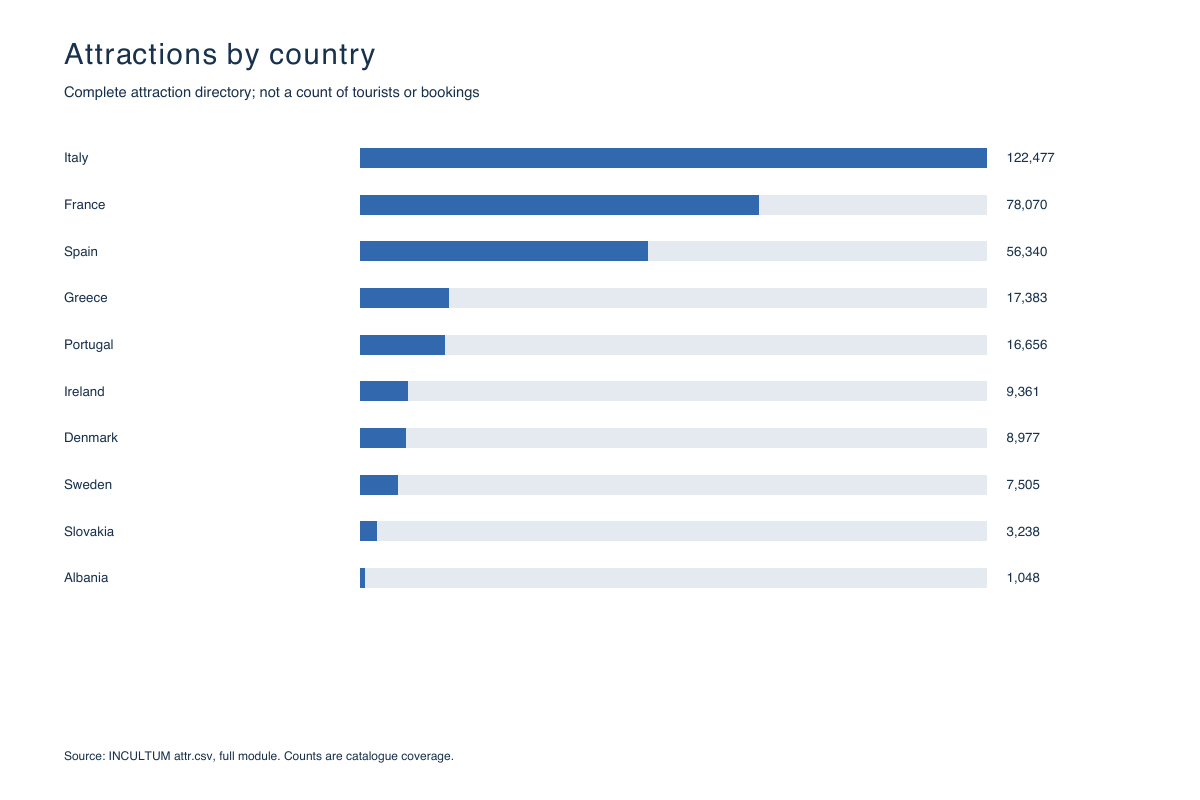

## Earlier EDA plot page 2

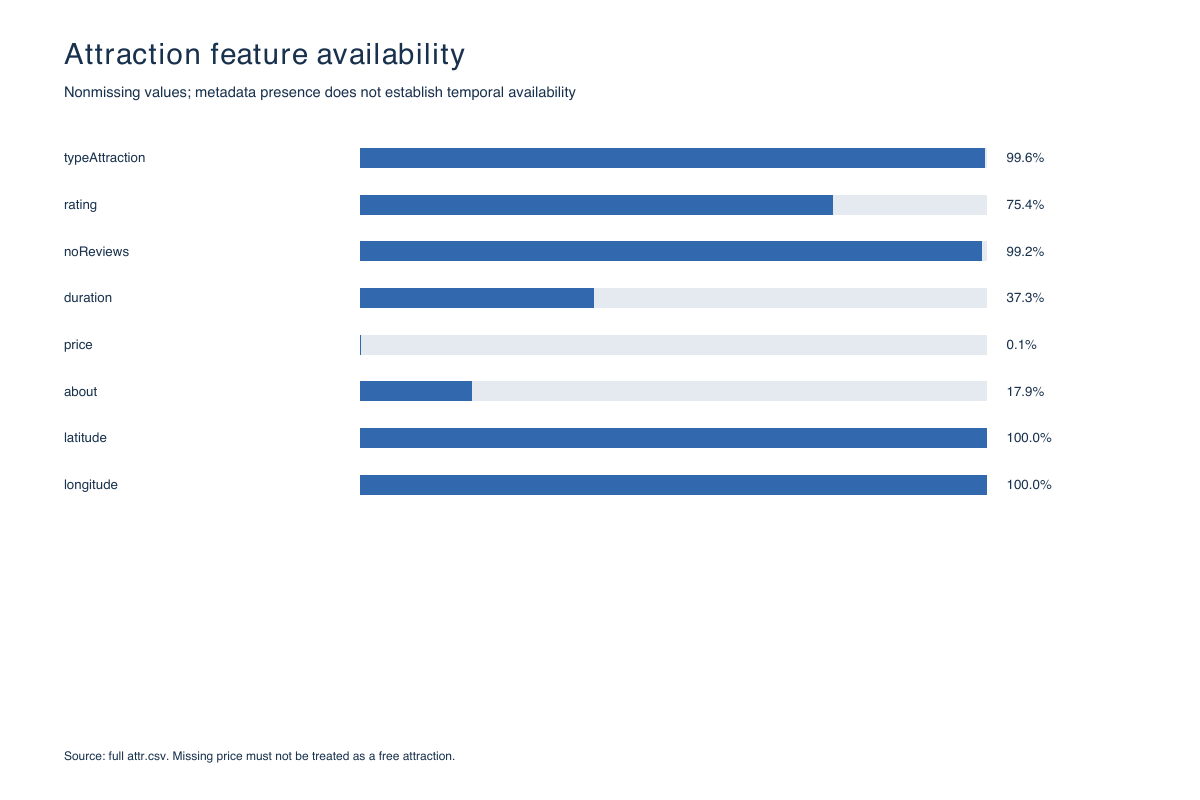

## Earlier EDA plot page 3

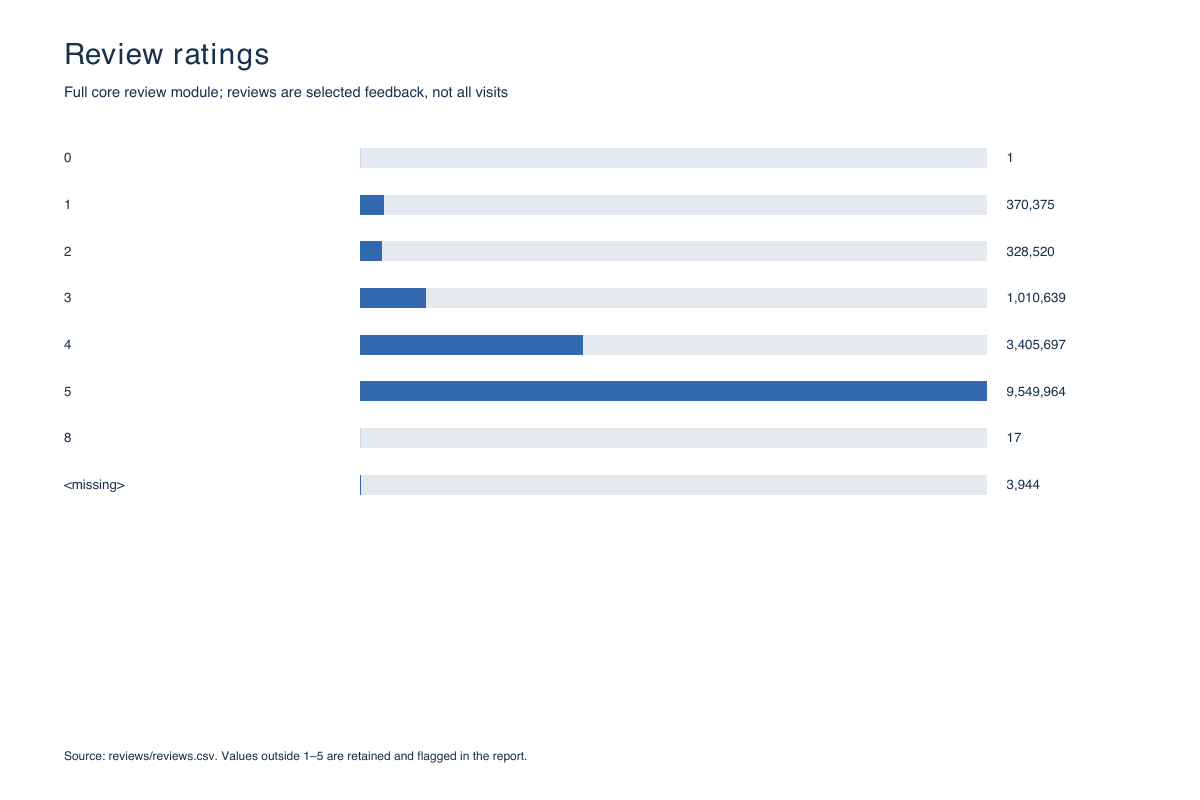

## Earlier EDA plot page 4

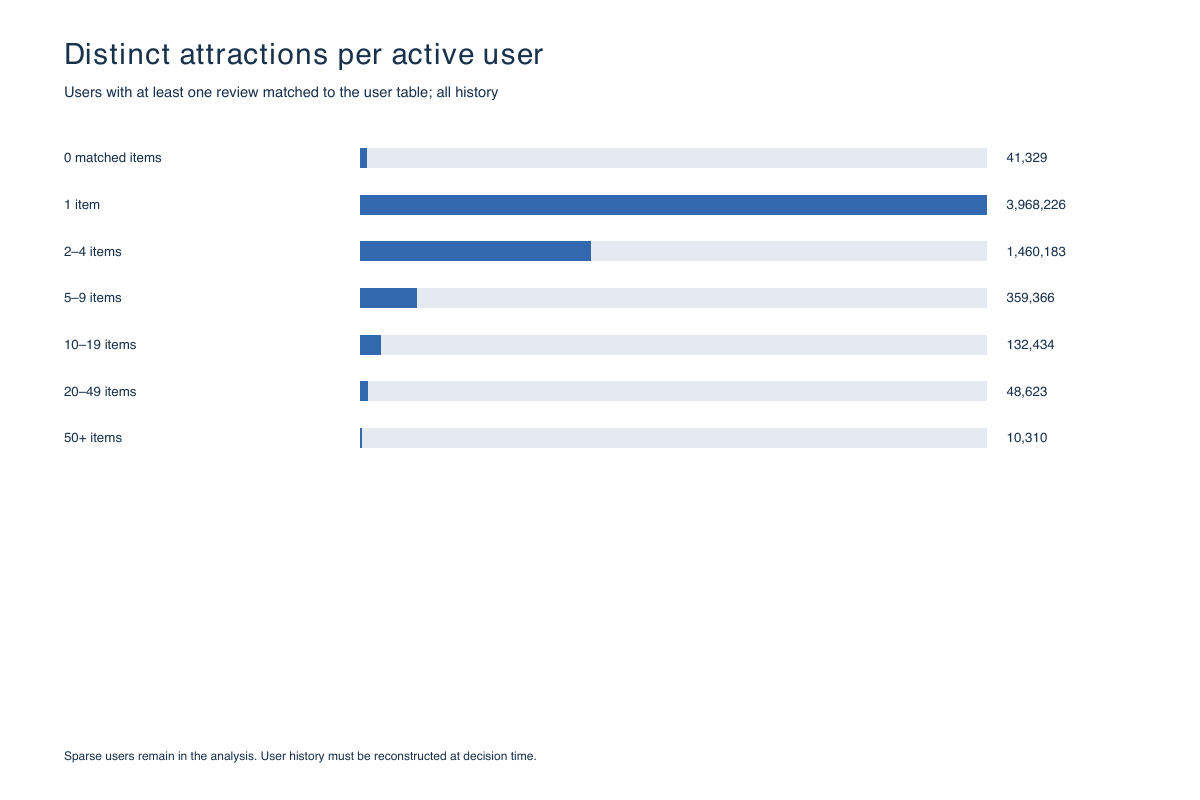

## Earlier EDA plot page 5

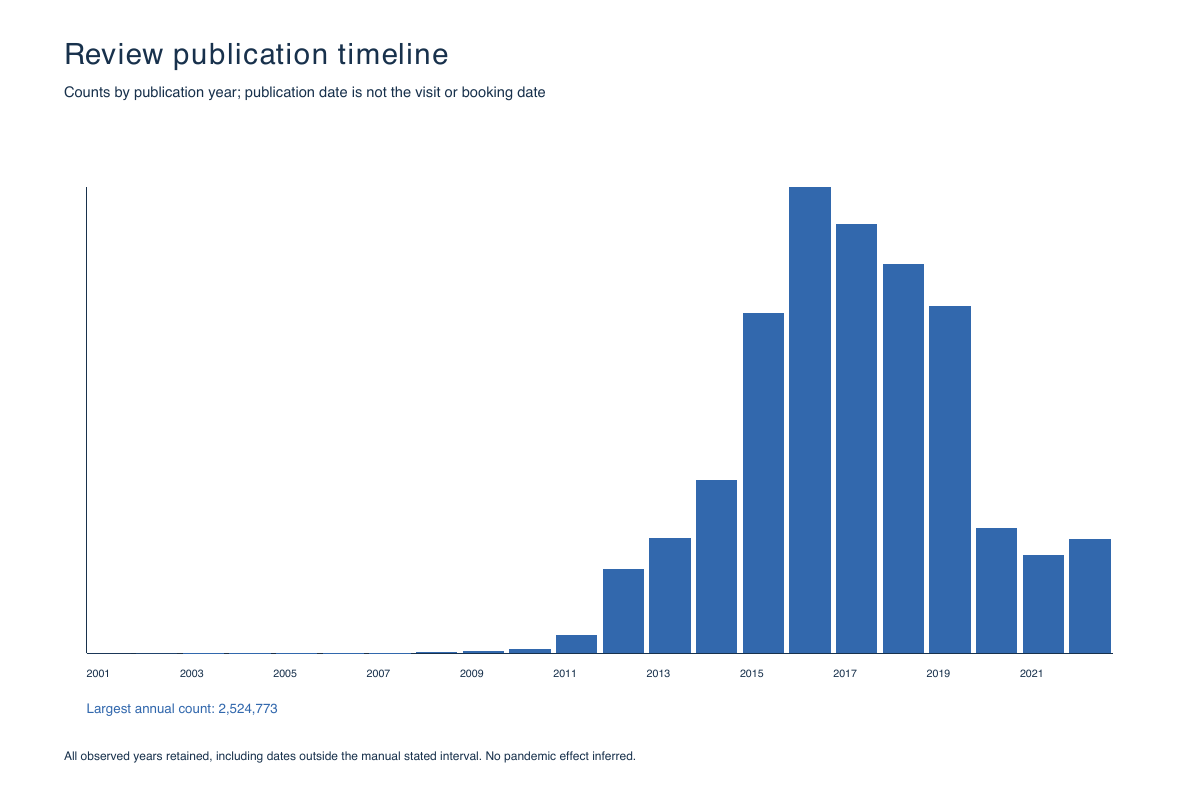

## Earlier EDA plot page 6

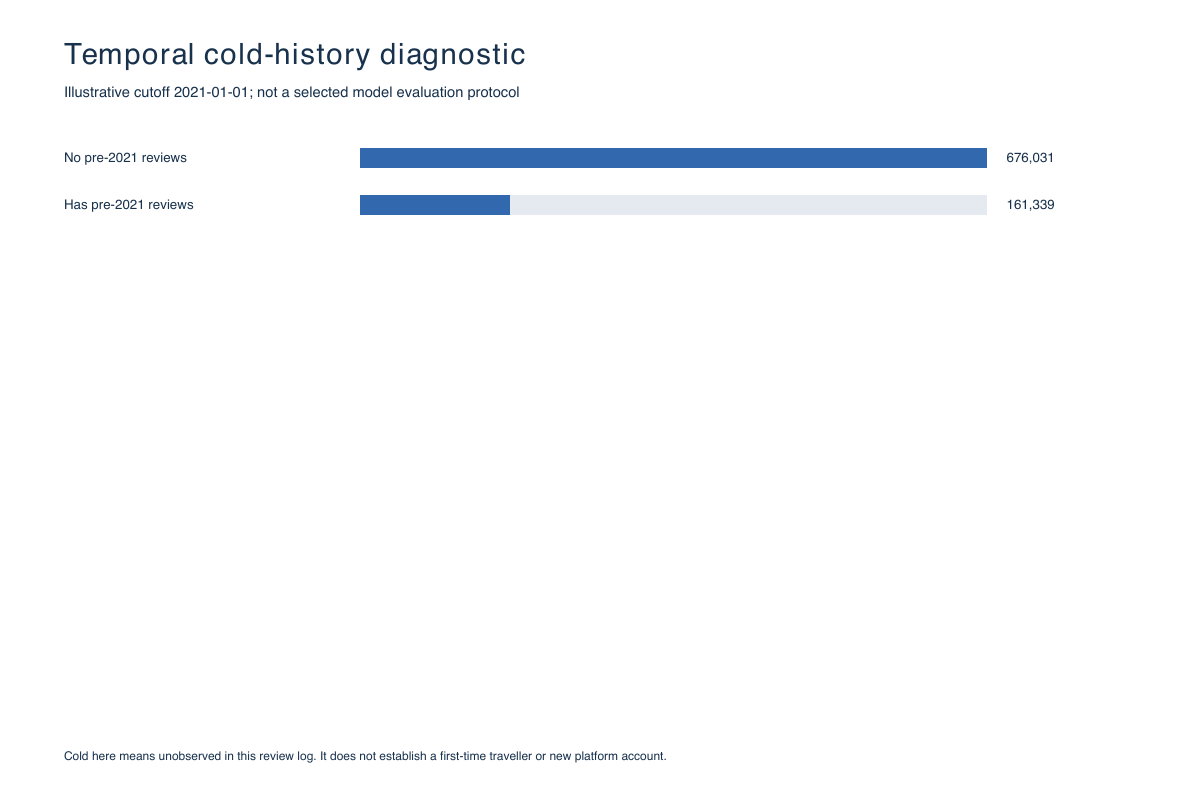